# FLow Matching训练和生成

# 1. 数据

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

torch.manual_seed(42)


def sample_data(n, device=device):
    labels = torch.randint(
        0,
        8,
        (n,),
        device=device,
    )

    angles = labels * (
        2 * math.pi / 8
    )

    centers = torch.stack([
        4 * torch.cos(angles),
        4 * torch.sin(angles),
    ], dim=1)

    return (
        centers
        + 0.25 * torch.randn(
            n,
            2,
            device=device,
        )
    )

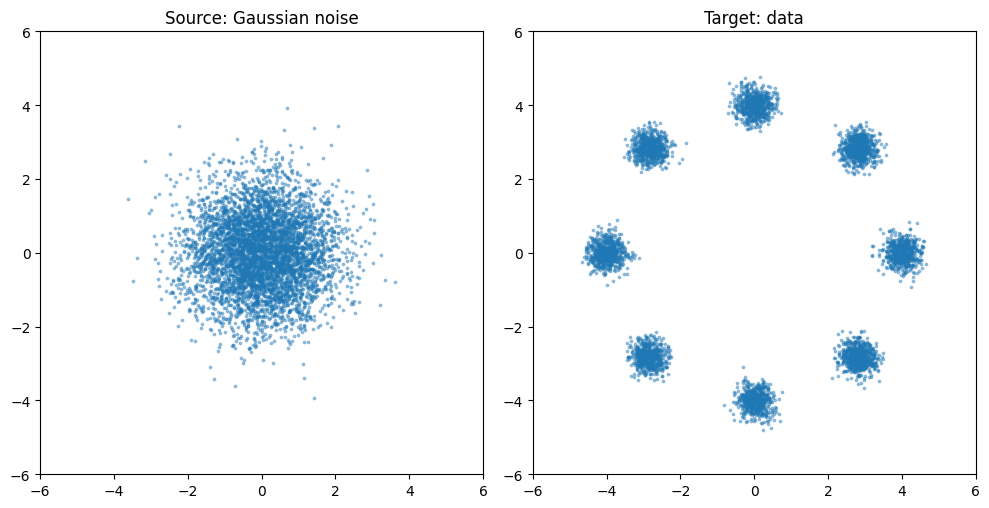

In [2]:
# 观察数据分布
noise_samples = torch.randn(
    5000,
    2,
    device=device,
)

data_samples = sample_data(5000)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 5),
)

axes[0].scatter(
    noise_samples[:, 0].cpu(),
    noise_samples[:, 1].cpu(),
    s=3,
    alpha=0.4,
)
axes[0].set_title("Source: Gaussian noise")

axes[1].scatter(
    data_samples[:, 0].cpu(),
    data_samples[:, 1].cpu(),
    s=3,
    alpha=0.4,
)
axes[1].set_title("Target: data")

for ax in axes:
    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

# 2. 模型

## 2.1 时间编码

In [3]:
class ContinuousTimeEmbedding(nn.Module):
    def __init__(self, dim=32):
        super().__init__()

        half_dim = dim // 2

        frequencies = torch.exp(
            torch.linspace(
                math.log(1.0),
                math.log(100.0),
                half_dim,
            )
        )

        self.register_buffer(
            "frequencies",
            frequencies,
        )

    def forward(self, t):
        # 同时支持 [B] 和 [B, 1]
        t = t.reshape(-1, 1)

        angles = (
            2 * math.pi
            * t
            * self.frequencies[None, :]
        )

        return torch.cat([
            torch.sin(angles),
            torch.cos(angles),
        ], dim=1)

## 2.2 速度预测网络

In [4]:
class FlowMLP(nn.Module):
    def __init__(
        self,
        time_dim=32,
        hidden_dim=256,
    ):
        super().__init__()

        self.time_embedding = (
            ContinuousTimeEmbedding(
                time_dim
            )
        )

        self.network = nn.Sequential(
            nn.Linear(
                2 + time_dim,
                hidden_dim,
            ),
            nn.SiLU(),

            nn.Linear(
                hidden_dim,
                hidden_dim,
            ),
            nn.SiLU(),

            nn.Linear(
                hidden_dim,
                hidden_dim,
            ),
            nn.SiLU(),

            nn.Linear(
                hidden_dim,
                2,
            ),
        )

    def forward(self, x, t):
        time_features = (
            self.time_embedding(t)
        )

        inputs = torch.cat([
            x,
            time_features,
        ], dim=1)

        return self.network(inputs)

# 3. 训练

In [5]:
flow_model = FlowMLP().to(device)

optimizer = torch.optim.Adam(
    flow_model.parameters(),
    lr=2e-3,
)

In [6]:
# 数据和标签
batch_size = 512

y = sample_data(batch_size)
z = torch.randn_like(y)

t = torch.rand(
    batch_size,
    1,
    device=device,
)

xt = (1.0 - t) * z + t * y
target_velocity = y - z

print("y:", y.shape)
print("z:", z.shape)
print("t:", t.shape)
print("xt:", xt.shape)
print(
    "target velocity:",
    target_velocity.shape,
)

y: torch.Size([512, 2])
z: torch.Size([512, 2])
t: torch.Size([512, 1])
xt: torch.Size([512, 2])
target velocity: torch.Size([512, 2])


In [7]:
# 训练
training_steps = 15000
batch_size = 512

loss_history = []

flow_model.train()

for step in range(training_steps):
    # 目标数据
    y = sample_data(batch_size)

    # 源高斯噪声
    z = torch.randn_like(y)

    # 连续时间
    t = torch.rand(
        batch_size,
        1,
        device=device,
    )

    # 条件直线路径
    xt = (
        (1.0 - t) * z
        + t * y
    )

    # 条件速度标签
    target_velocity = y - z

    # 网络预测边缘速度
    predicted_velocity = flow_model(
        xt,
        t,
    )

    loss = F.mse_loss(
        predicted_velocity,
        target_velocity,
    )

    optimizer.zero_grad()
    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        flow_model.parameters(),
        max_norm=1.0,
    )

    optimizer.step()

    loss_history.append(loss.item())

    if (step + 1) % 1000 == 0:
        print(
            f"step={step + 1}, "
            f"loss={loss.item():.4f}"
        )

step=1000, loss=3.9791
step=2000, loss=3.7992
step=3000, loss=3.6065
step=4000, loss=3.8768
step=5000, loss=3.2127
step=6000, loss=3.7441
step=7000, loss=3.9455
step=8000, loss=3.9132
step=9000, loss=3.8405
step=10000, loss=2.9518
step=11000, loss=3.3394
step=12000, loss=4.0652
step=13000, loss=3.3108
step=14000, loss=3.3050
step=15000, loss=4.1573


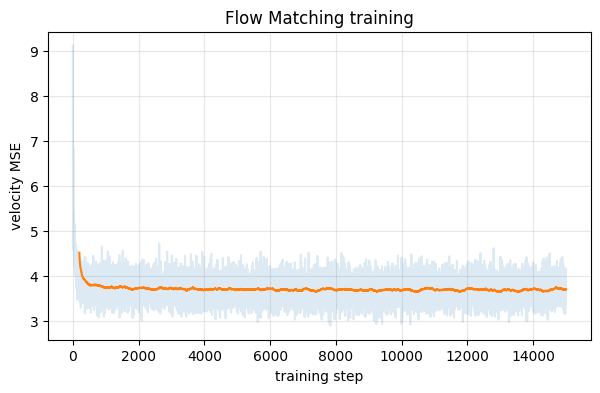

In [8]:
import numpy as np

loss_array = np.array(loss_history)

window = 200

smoothed_loss = np.convolve(
    loss_array,
    np.ones(window) / window,
    mode="valid",
)

plt.figure(figsize=(7, 4))

plt.plot(
    loss_array,
    alpha=0.15,
)

plt.plot(
    range(window - 1, len(loss_array)),
    smoothed_loss,
)

plt.xlabel("training step")
plt.ylabel("velocity MSE")
plt.title("Flow Matching training")
plt.grid(alpha=0.3)
plt.show()

# 4. 使用Euler方法求解ODE

In [9]:
@torch.no_grad()
def sample_flow_euler(
    model,
    n_samples=5000,
    num_steps=100,
    initial_noise=None,
    save_trajectory=False,
):
    model.eval()

    if initial_noise is None:
        x = torch.randn(
            n_samples,
            2,
            device=device,
        )
    else:
        x = initial_noise.clone().to(device)
        n_samples = x.shape[0]

    dt = 1.0 / num_steps

    snapshots = {
        0.0: x.detach().cpu()
    }

    save_indices = {
        num_steps // 4,
        num_steps // 2,
        3 * num_steps // 4,
        num_steps,
    }

    for step in range(num_steps):
        t_value = step / num_steps

        t = torch.full(
            (n_samples, 1),
            t_value,
            device=device,
        )

        velocity = model(x, t)

        x = x + dt * velocity

        if save_trajectory and (
            step + 1 in save_indices
        ):
            current_time = (
                step + 1
            ) / num_steps

            snapshots[current_time] = (
                x.detach().cpu()
            )

    return x.detach().cpu(), snapshots

In [11]:
generated, snapshots = (
    sample_flow_euler(
        flow_model,
        n_samples=5000,
        num_steps=100,
        save_trajectory=True,
    )
)

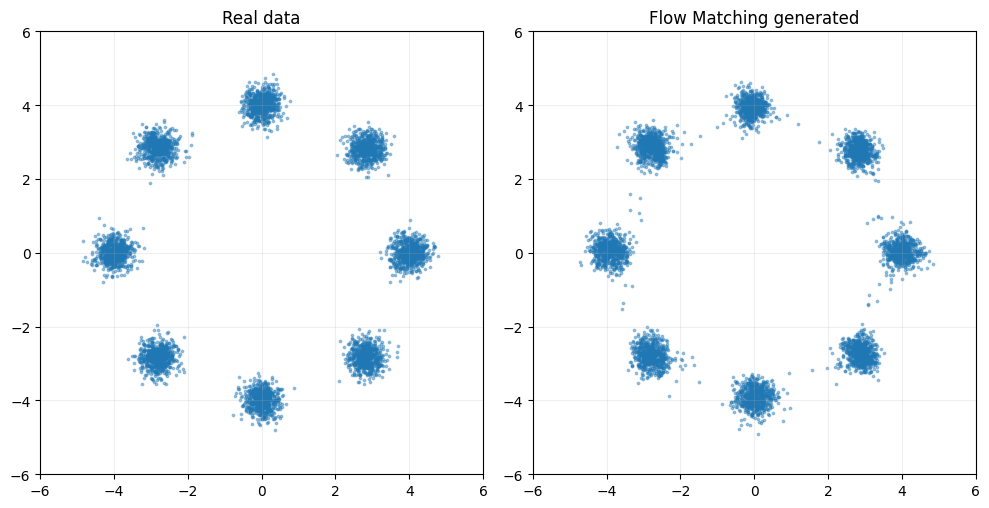

In [12]:
real = sample_data(
    5000,
    device="cpu",
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 5),
)

axes[0].scatter(
    real[:, 0],
    real[:, 1],
    s=3,
    alpha=0.4,
)
axes[0].set_title("Real data")

axes[1].scatter(
    generated[:, 0],
    generated[:, 1],
    s=3,
    alpha=0.4,
)
axes[1].set_title(
    "Flow Matching generated"
)

for ax in axes:
    ax.set_xlim(-6, 6)
    ax.set_ylim(-6, 6)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()